# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:**
- Устройство: colab T4
- Модель: [`cointegrated/rubert-tiny2`](https://huggingface.co/cointegrated/rubert-tiny2), revision `e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae`, лицензия MIT
- Датасет: Collection3, [`RCC-MSU/collection3`](https://huggingface.co/datasets/RCC-MSU/collection3), ветка `refs/convert/parquet` (коммит `2398327de1579acc44942636f27b8de1dcc69c1b`). в карточке лицензия `other`
- Бонусы: 6.2, 6.3, 6.4, 6.5
- Источники: документация hugging face, документация seqeval, материалы курса
- Нерешенные задачи: 6.1

In [36]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

In [37]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

torch 2.14.1+cu130, transformers 5.22.1, datasets 5.1.0
CUDA available: True


In [38]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

cuda Tesla T4


In [39]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}   # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [40]:
MODEL_ID = 'cointegrated/rubert-tiny2'   # ваш код: id модели на Hugging Face Hub
REVISION = 'e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae'   # ваш код: полный commit hash (40 символов)
TOKENIZER_KWARGS = {}   # для roberta-base: {'add_prefix_space': True}

In [41]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    cointegrated/rubert-tiny2
revision: e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae
license:  mit
language: ['ru']
updated:  2025-12-30 08:33:24+00:00
weights:  {'model.safetensors': '112 MB', 'pytorch_model.bin': '112 MB'}
BertTokenizer vocab size 83828
['Петр', 'Ильич', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** rubert-tiny2 - маленький bert для русского языка (примерно 29M параметров, 3 слоя, hidden 312, словарь 83.8k сабвордов, контекст до 2048 токенов). Из LaBSE и дообучали на русских и русско-английских корпусах, поэтому токенизатор хорошо режет русские слова: в среднем 1.14 сабворда на слово в Collection3. Модель быстрая - прямой проход батча 32×64 занимает единицы миллисекунд на T4. Лицензия MIT. Альтернативы: DeepPavlov/rubert-base-cased ( примерно 180M, 12 слоев, hidden 768, русская википедия и новости) на NER обычно дает F1 на несколько пунктов выше, но в где-то 6 раз больше и медленнее, лицензия в карточке не указана. xlm-roberta-base ( примерно 280M, 100 языков, словарь 250k) почти на 70% состоит из эмбеддингов и для русского по качеству близок к ruBERT-base при гораздо большей стоимости, его сравниваю в 6.2. Без фиксации revision через полгода main может указывать на другие веса или токенизатор (rubert-tiny2 уже обновлялся). Тогда изменятся сабворды и word_ids, метрики перестанут воспроизводиться, при смене словаря или конфига загрузка может упасть или дать другую модель

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [42]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'model_type': 'bert', 'vocab_size': 83828, 'hidden_size': 312, 'num_hidden_layers': 3, 'num_attention_heads': 12, 'intermediate_size': 600, 'max_position_embeddings': 2048}
bert         BertModel
dropout      Dropout
classifier   Linear


In [43]:
def params_by_block(model):
    # -> {'embeddings': int, 'encoder': int, 'head': int, 'other': int, 'layers': [int, ...]}
    def count(module):
        return sum(p.numel() for p in module.parameters())

    base = getattr(model, model.base_model_prefix)   # BertModel внутри BertForTokenClassification
    layers = [count(layer) for layer in base.encoder.layer]
    embeddings = count(base.embeddings)
    encoder = sum(layers)
    head = count(model.classifier)
    total = count(model)
    return dict(embeddings=embeddings, encoder=encoder, head=head,
                other=total - embeddings - encoder - head, layers=layers)

In [44]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    26,794,560   92.1%
encoder        2,301,552    7.9%
head               2,191    0.0%
other                  0    0.0%
total         29,098,303
per layer: [767184, 767184, 767184]


In [45]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
demo_model.eval()
with torch.no_grad():
    out = demo_model(**enc, output_hidden_states=True)

print('input_ids     ', tuple(enc['input_ids'].shape))
print('attention_mask', tuple(enc['attention_mask'].shape))
for i, h in enumerate(out.hidden_states):
    print(f'hidden_states[{i}]', tuple(h.shape), '(выход эмбеддингов)' if i == 0 else f'(выход слоя {i})')
print('logits        ', tuple(out.logits.shape))
for i in range(len(demo_texts)):
    print(list(zip(enc.tokens(i), enc.word_ids(i))))

input_ids      (2, 11)
attention_mask (2, 11)
hidden_states[0] (2, 11, 312) (выход эмбеддингов)
hidden_states[1] (2, 11, 312) (выход слоя 1)
hidden_states[2] (2, 11, 312) (выход слоя 2)
hidden_states[3] (2, 11, 312) (выход слоя 3)
logits         (2, 11, 7)
[('[CLS]', None), ('Петр', 0), ('Чайк', 1), ('##овский', 1), ('родился', 2), ('в', 3), ('Вот', 4), ('##кинс', 4), ('##ке', 4), ('.', 5), ('[SEP]', None)]
[('[CLS]', None), ('IT', 0), ('##M', 0), ('##O', 0), ('University', 1), ('is', 2), ('in', 3), ('Saint', 4), ('Petersburg', 5), ('[SEP]', None), ('[PAD]', None)]


In [46]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 6.7 ms на Tesla T4


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:** путь входа: два предложения по 6 слов - токенизатор - input_ids и attention_mask формы (2, 11). Первое предложение режется на 9 сабвордов (Чайк ##овский, Вот ##кинс ##ке) + [CLS] и [SEP], второе на 8 + 2 = 10 сабвордов и дополняется паддингом до 11. Эмбеддинги дают hidden_states[0] формы (2, 11, 312). Каждый из 3 слоев энкодера сохраняет форму: hidden_states[1..3] тоже (2, 11, 312), всего 4 тензора. Linear(312, 7) дает logits формы (2, 11, 7). Больше всего параметров в эмбеддингах: 26.8M из 29.1M (92%), из них таблица сабвордов 83828 × 312 = 26.2M. На каждый из 3 слоев приходится всего 0.77M (2.30M на энкодер, 8%), голова 2191 параметр. Так получается, потому что словарь большой, а hidden маленький и слоев мало. Обмен информацией между токенами идет только в слоях энкодера. Эмбеддинги (кроме позиционной добавки) и голова обрабатывают каждый токен независимо. T в logits больше числа слов, потому что логиты считаются на каждый сабворд: редкие слова режутся на несколько сабвордов, плюс спецтокены [CLS]/[SEP] и паддинг до самого длинного в батче (62 слова "слово" - T = 64)

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [47]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [48]:
DATASET_ID, DATASET_CONFIG = 'RCC-MSU/collection3', None   # ваш код
DATASET_REVISION = 'refs/convert/parquet'   # на 22.11.2026 эта ветка указывает на коммит 2398327de1579acc44942636f27b8de1dcc69c1b
raw = load_dataset(DATASET_ID, revision=DATASET_REVISION)   # ваш код: загрузите датасет
raw = DatasetDict({split: raw[split].select_columns(['tokens', 'ner_tags']) for split in ['train', 'validation', 'test']})

tag_feature = getattr(raw['train'].features['ner_tags'], 'feature', None)
LABEL_NAMES = list(getattr(tag_feature, 'names', None) or ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC'])   # ваш код
print(raw)
print(LABEL_NAMES)

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 1922
    })
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']


split         sent  no ent    LOC    ORG    PER   total
train         9301    1815   4881   5960   7406   18247
validation    2153     504   1168   1308   1641    4117
test          1922     351   1175   1256   1570    4001

длина спана в словах (train):
  1:   9025   49.5%
  2:   6124   33.6%
  3:   2068   11.3%
  4:    373    2.0%
  5:    206    1.1%
  6:    238    1.3%
  7:     71    0.4%
  8:     68    0.4%
  >8:     74
длина предложения train       mean 20.2, median 18, p95 41, max 256
длина предложения validation  mean 20.4, median 18, p95 41, max 118
длина предложения test        mean 20.9, median 19, p95 42, max 122


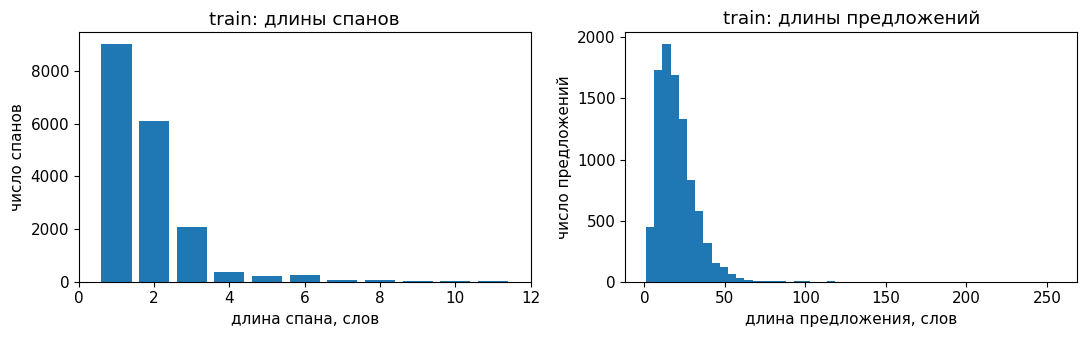

In [49]:
# ваша статистика: сущности по типам и сплитам, длины спанов в словах, длины предложений
from seqeval.metrics.sequence_labeling import get_entities

stats = {}
for split in ['train', 'validation', 'test']:
    type_counts, span_lens, sent_lens, n_empty = collections.Counter(), collections.Counter(), [], 0
    for ex in raw[split]:
        ents = get_entities([LABEL_NAMES[i] for i in ex['ner_tags']])
        sent_lens.append(len(ex['tokens']))
        n_empty += not ents
        for typ, start, end in ents:
            type_counts[typ] += 1
            span_lens[end - start + 1] += 1
    stats[split] = dict(types=type_counts, span_lens=span_lens, sent_lens=np.array(sent_lens), n_empty=n_empty)

types = sorted({t for s in stats.values() for t in s['types']})
print(f'{"split":<11}{"sent":>7}{"no ent":>8}' + ''.join(f'{t:>7}' for t in types) + f'{"total":>8}')
for split, s in stats.items():
    print(f'{split:<11}{len(s["sent_lens"]):>7}{s["n_empty"]:>8}' + ''.join(f'{s["types"][t]:>7}' for t in types)
          + f'{sum(s["types"].values()):>8}')

print('\nдлина спана в словах (train):')
train_lens = stats['train']['span_lens']
n_spans = sum(train_lens.values())
for k in sorted(train_lens)[:8]:
    print(f'  {k}: {train_lens[k]:>6}  {train_lens[k] / n_spans:6.1%}')
print(f'  >8: {sum(v for k, v in train_lens.items() if k > 8):>6}')

for split, s in stats.items():
    lens = s['sent_lens']
    print(f'длина предложения {split:<11} mean {lens.mean():.1f}, median {np.median(lens):.0f}, '
          f'p95 {np.percentile(lens, 95):.0f}, max {lens.max()}')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].bar(sorted(train_lens), [train_lens[k] for k in sorted(train_lens)])
axes[0].set(xlabel='длина спана, слов', ylabel='число спанов', title='train: длины спанов', xlim=(0, 12))
axes[1].hist(stats['train']['sent_lens'], bins=50)
axes[1].set(xlabel='длина предложения, слов', ylabel='число предложений', title='train: длины предложений')
plt.tight_layout()
plt.show()

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:** collection3 (НИВЦ МГУ, RCC-MSU) - русские новостные тексты: корпус Persons-1000 расширили разметкой ORG и LOC. Разметка ручная, экспертная. Лицензия в карточке HF - other. Типы PER / ORG / LOC в BIO. Сплиты: train 9301 предложений (PER 7406, ORG 5960, LOC 4881), validation 2153 (PER 1641, ORG 1308, LOC 1168), test 1922 (PER 1570, ORG 1256, LOC 1175). Явно редких типов нет, но LOC меньше всего, а ORG самый разнообразный (аббревиатуры, длинные названия). Спаны короткие: в train 49% длиной 1 слово, 34% - 2 слова, 11% - 3 слова, а длиннее 3 слов около 6% - это в основном полные названия организаций. Предложения в среднем 20 слов (медиана 18, максимум 256 в train), около 23% предложений validation без сущностей вообще. Шум разметки: в train 5 предложений с I-X без B-X (в test 1), есть «склеенные» токены и пунктуация внутри названий (пресс - службе). Метки типа зависят от контекста (России бывает и LOC, и частью ORG), это ограничивает словарные подходы

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [50]:
def bio_to_spans(tags):
    # ['B-PER', 'I-PER', 'O', 'B-LOC'] -> [(0, 2, 'PER'), (3, 4, 'LOC')]
    spans, start, typ = [], None, None
    for i, tag in enumerate(list(tags) + ['O']):
        if tag == 'O':
            new = None
        else:
            prefix, new = tag.split('-', 1)
            if prefix == 'I' and new == typ:
                continue
        if typ is not None:
            spans.append((start, i, typ))
        start, typ = (i, new) if new is not None else (None, None)
    return spans


def spans_to_bio(spans, n_words):
    # [(0, 2, 'PER')], 3 -> ['B-PER', 'I-PER', 'O']
    tags = ['O'] * n_words
    for start, end, typ in spans:
        tags[start] = 'B-' + typ
        for i in range(start + 1, end):
            tags[i] = 'I-' + typ
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    labels, prev = [], None
    for w in word_ids:
        if w is None:
            labels.append(-100)
        elif w != prev:
            labels.append(word_labels[w])
        elif b_to_i is not None:
            labels.append(b_to_i.get(word_labels[w], word_labels[w]))
        else:
            labels.append(-100)
        prev = w
    return labels

In [51]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]
print('ok')

ok


In [52]:
# если датасет не в формате «слова + BIO»: конвертация в контракт из 2.1
# если уже в BIO: экспорт в спаны JSON (data/<split>_spans.jsonl), чтение обратно, BIO, сравнение с исходным
DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)

for split in ['train', 'validation', 'test']:
    path = DATA_DIR / f'{split}_spans.jsonl'
    with path.open('w', encoding='utf-8') as f:
        for ex in raw[split]:
            spans = bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
            f.write(json.dumps({'tokens': list(ex['tokens']), 'spans': [list(s) for s in spans]}, ensure_ascii=False) + '\n')

    n_same, bad_examples = 0, []
    with path.open(encoding='utf-8') as f:
        records = [json.loads(line) for line in f]
    assert len(records) == len(raw[split])
    for idx, (rec, ex) in enumerate(zip(records, raw[split])):
        assert rec['tokens'] == list(ex['tokens'])
        spans = [tuple(s) for s in rec['spans']]
        assert all(0 <= s < e <= len(rec['tokens']) for s, e, _ in spans)
        assert all(a[1] <= b[0] for a, b in zip(spans, spans[1:])), 'спаны не пересекаются и идут по порядку'
        orig = [LABEL_NAMES[i] for i in ex['ner_tags']]
        back = spans_to_bio(spans, len(rec['tokens']))
        assert bio_to_spans(back) == bio_to_spans(orig) == spans
        if back == orig:
            n_same += 1
        else:
            bad_examples.append(idx)
    print(f'{split:<11} {path}: {len(records)} предложений, {sum(len(r["spans"]) for r in records)} спанов, '
          f'BIO совпало дословно {n_same}, с I- без B- {len(bad_examples)}')
    for idx in bad_examples[:2]:
        ex = raw[split][idx]
        print('   ', [(w, LABEL_NAMES[t]) for w, t in zip(ex['tokens'], ex['ner_tags']) if t != 0])


def normalize_bio(ex):
    tags = spans_to_bio(bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']]), len(ex['tokens']))
    return {'ner_tags': [LABEL_NAMES.index(t) for t in tags]}


raw = raw.map(normalize_bio)
example_rec = json.loads((DATA_DIR / 'train_spans.jsonl').open(encoding='utf-8').readline())
print('пример записи:', example_rec)

train       data/train_spans.jsonl: 9301 предложений, 18247 спанов, BIO совпало дословно 9296, с I- без B- 5
    [('Мособлдума', 'B-ORG'), ('Воробьева', 'B-PER'), ('о', 'I-PER'), ('Подмосковья', 'B-LOC')]
    [('Власть', 'I-ORG'), ('Вероника', 'B-PER'), ('Куцылло', 'I-PER')]
validation  data/validation_spans.jsonl: 2153 предложений, 4117 спанов, BIO совпало дословно 2153, с I- без B- 0
test        data/test_spans.jsonl: 1922 предложений, 4001 спанов, BIO совпало дословно 1921, с I- без B- 1
    [('Первоуральск', 'I-ORG'), ('Ольгу', 'B-PER'), ('Вертлюгову', 'I-PER')]
пример записи: {'tokens': ['Дополнение', ':', 'Д', '.', 'Медведев', 'присвоил', 'звания', 'сотрудников', 'полиции', 'и', 'переназначил', '14', 'руководителей', 'УВД', ',', 'ГУВД', 'и', 'МВД', 'по', 'субъектам', 'РФ', '.'], 'spans': [[2, 5, 'PER'], [13, 14, 'ORG'], [15, 16, 'ORG'], [17, 18, 'ORG'], [20, 21, 'LOC']]}


In [53]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 1922
    })
})
ENTITY_TYPES ['LOC', 'ORG', 'PER']
train: проверено 9288 предложений, обрезано по MAX_LENGTH 10, слов без сабвордов или за обрезкой 434
[CLS]            None  -100
До                  0  O
##полнение          0  -100
:                   1  O
Д                   2  B-PER
.                   3  I-PER
Медведев            4  I-PER
присвоил            5  O
звания              6  O
сотрудников         7  O
полиции             8  O
и                   9  O
перена             10  O
##зна              10  -100
##чил              10  -100
14                 11  O
руководителей      12  O
УВД                13  B-ORG
,                  14  O
ГУВД               15  B-ORG
и                  16  O
МВД    

**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:** тег предсказывается для слова, а слово может резаться на несколько сабвордов. Если поставить метку на все сабворды, длинные слова получат больший вес в loss, а продолжения станут отдельными объектами с непонятным тегом (B или I). Поэтому метку ставим на первый сабворд, предсказание тоже читаем с него. Значение -100 - это ignore_index cross-entropy: не входят ни в loss, ни в градиент, ни в нормировку среднего. При полном train по MAX_LENGTH = 128 обрезано 10 предложений, без сабвордов или за обрезкой остается 434 слова train (из ~188 тыс.). На метрику это почти не влияет: такие слова получают O, и потерянные сущности в хвостах длинных предложений идут в recall как пропуски. При конвертации нашлось: несколько предложений с I-X без B-X. Спаны при этом совпадают (seqeval считает такой I- началом), но BIO дословно не совпадает, поэтому разметку я нормализовала (I-X -> B-X). Пересекающихся и вложенных спанов в плоском BIO быть не может, расхождений слов между JSON и исходником нет

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [54]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [55]:
def fit_majority_tagger(tokens_list, tags_list):
    # -> dict: слово -> самый частый тег этого слова в train
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list):
        for word, tag in zip(words, tags):
            counts[word][tag] += 1
    return {word: c.most_common(1)[0][0] for word, c in counts.items()}


def predict_majority(tagger, words):
    # -> список тегов той же длины; незнакомое слово -> 'O'
    return [tagger.get(word, 'O') for word in words]

In [56]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

baseline = {}   # ваш код: baseline['majority'] и baseline['random_head'] - словари entity_scores
train_tokens = [list(ws) for ws in data['train']['tokens']]
train_tags = [[LABEL_NAMES[i] for i in tags] for tags in data['train']['ner_tags']]
majority = fit_majority_tagger(train_tokens, train_tags)
majority_pred = [predict_majority(majority, ws) for ws in val_tokens]
baseline['majority'] = entity_scores(val_gold, majority_pred)
n_val_words = sum(len(ws) for ws in val_tokens)
n_oov = sum(w not in majority for ws in val_tokens for w in ws)
print(f'словарь {len(majority)} слов, незнакомых слов в validation {n_oov / n_val_words:.1%}')

set_seed(SEED)
random_model = make_model()
random_pred = predict_word_tags(random_model, val_tokens)
baseline['random_head'] = entity_scores(val_gold, random_pred)
pred_tag_counts = collections.Counter(t for tags in random_pred for t in tags)
gold_tag_counts = collections.Counter(t for tags in val_gold for t in tags)
print('теги случайной головы:', dict(pred_tag_counts.most_common()))
print('истинные теги:        ', dict(gold_tag_counts.most_common()))
random_model.cpu()
del random_model

for name, scores in baseline.items():
    print(f'{name:<12}' + '  '.join(f'{k} {v:.4f}' for k, v in scores.items()))

словарь 27410 слов, незнакомых слов в validation 11.2%


Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

теги случайной головы: {'O': 11544, 'I-PER': 11459, 'B-PER': 8688, 'I-LOC': 4833, 'B-LOC': 3053, 'I-ORG': 2511, 'B-ORG': 1768}
истинные теги:         {'O': 36570, 'B-PER': 1641, 'I-PER': 1615, 'B-ORG': 1308, 'I-ORG': 1199, 'B-LOC': 1168, 'I-LOC': 355}
majority    f1_micro 0.5615  f1_macro 0.5787  precision 0.5629  recall 0.5601
random_head f1_micro 0.0381  f1_macro 0.0353  precision 0.0223  recall 0.1304


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:** словарный бейзлайн на полном train дает F1 по сущностям 0.56 на validation (P 0.563, R 0.560, macro 0.58). В словаре 27410 слов, незнакомых слов в validation 11.2%. Он работает за счет того, что в новостях одни и те же сущности (страны, города, ведомства, политики) часто повторяются. Проигрывает он на незнакомых словах, которые всегда получают O, на многословных спанах (каждое слово размечается отдельно, и B/I могут не сложиться в правильный спан) и на контекстно зависимых словах (России в "Президент России" - LOC, а в "МВД России" - часть ORG). Энкодер со случайной головой дает F1 0.038 (P 0.022, R 0.130): голова Linear(312, 7) инициализирована случайно и ничего не знает о метках, так что argmax определяется случайными весами. Это видно по распределению тегов: O получают только 11544 слова, тогда как в разметке O у 36570 слов (85%), а B-PER и I-PER модель ставит примерно 20 тыс. словам против 3.3 тыс. истинных. Отсюда много лишних спанов и очень низкая precision, а recall 0.13 - случайные попадания. Энкодер предобучен и дает осмысленные признаки, но отображение признаков в теги не обучено, поэтому спаны с правильными границами и типом появляются только случайно

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [57]:
LR = 2e-4          # подобрано под rubert-tiny2; у base-моделей обычно 2e-5 - 5e-5, выберите под свою модель
BATCH_SIZE = 32    # уменьшите, если не влезает в память T4
WARMUP_RATIO = 0.1
WEIGHT_DECAY = 0.01


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    # -> (history, seconds); history - список dict со 'step' и 'loss' или 'eval_loss'
    tok = tok or tokenizer
    if freeze_encoder:
        for p in getattr(model, model.base_model_prefix).parameters():
            p.requires_grad = False
    total_steps = math.ceil(len(train_ds) / batch_size) * epochs
    log_every = max(1, total_steps // 20)
    args = TrainingArguments(
        output_dir=out_dir, num_train_epochs=epochs, learning_rate=lr,
        per_device_train_batch_size=batch_size, per_device_eval_batch_size=batch_size * 2,
        warmup_steps=int(WARMUP_RATIO * total_steps), weight_decay=WEIGHT_DECAY, lr_scheduler_type='linear',
        eval_strategy='steps', eval_steps=log_every, logging_strategy='steps', logging_steps=log_every,
        save_strategy='no', report_to='none', fp16=torch.cuda.is_available(), seed=SEED)
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                      data_collator=DataCollatorForTokenClassification(tok), processing_class=tok)
    start = time.perf_counter()
    trainer.train()
    seconds = time.perf_counter() - start
    return trainer.state.log_history, seconds

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '1.134', 'grad_norm': '1.084', 'learning_rate': '9.655e-05', 'epoch': '0.1478'}
{'eval_loss': '0.4209', 'eval_runtime': '1.332', 'eval_samples_per_second': '1617', 'eval_steps_per_second': '25.53', 'epoch': '0.1478'}
{'loss': '0.2779', 'grad_norm': '1.353', 'learning_rate': '0.0001954', 'epoch': '0.2955'}
{'eval_loss': '0.1395', 'eval_runtime': '1.934', 'eval_samples_per_second': '1113', 'eval_steps_per_second': '17.58', 'epoch': '0.2955'}
{'loss': '0.137', 'grad_norm': '2.026', 'learning_rate': '0.0001896', 'epoch': '0.4433'}
{'eval_loss': '0.0774', 'eval_runtime': '1.434', 'eval_samples_per_second': '1502', 'eval_steps_per_second': '23.71', 'epoch': '0.4433'}
{'loss': '0.0998', 'grad_norm': '0.6863', 'learning_rate': '0.0001786', 'epoch': '0.5911'}
{'eval_loss': '0.07373', 'eval_runtime': '1.416', 'eval_samples_per_second': '1520', 'eval_steps_per_second': '24.01', 'epoch': '0.5911'}
{'loss': '0.08305', 'grad_norm': '1.363', 'learning_rate': '0.0001677', 'epoch': '0.7388'}
{

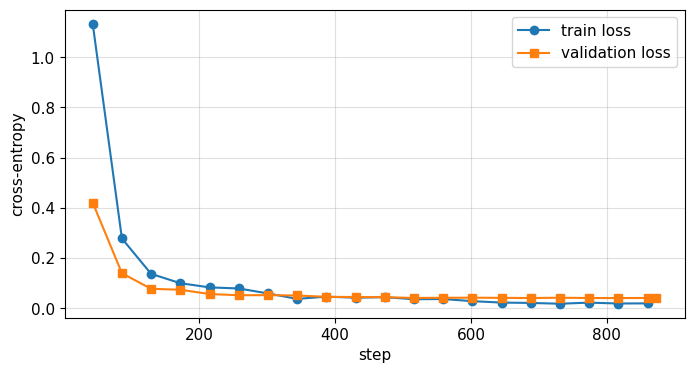

In [58]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:** гиперпараметры: LR = 2e-4. Модель маленькая (3 слоя, hidden 312), при 2e-5 - 5e-5, типичных для base-моделей, она недообучается за 3 эпохи. Batch 32 - баланс между шумом градиента и числом шагов (около 291 шага на эпоху на полном train). 3 эпохи, warmup 10% шагов (чтобы случайная голова в начале не разрушила предобученные веса большими градиентами), линейное затухание LR, weight decay 0.01, fp16 на T4. На кривых validation loss быстро падает в первой эпохе (с 0.42 до 0.05), во второй медленно снижается до ~0.041 и в третьей выходит на плато (финальный 0.041). Train loss опускается до ~0.03, а validation loss при этом не растет, поэтому переобучения нет. Но и заметного запаса для улучшения от дополнительных эпох не видно: кривая уже почти плоская, больше эпох дали бы максимум доли пункта F1. Обучение на полном train (9301 предложение, 3 эпохи) заняло 93.7 с на Tesla T4 (Colab)

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [59]:
def token_f1(gold, pred):
    # gold, pred: списки списков BIO-тегов -> micro-F1 по словам без тега O
    tp = n_pred = n_gold = 0
    for gold_tags, pred_tags in zip(gold, pred):
        for g, p in zip(gold_tags, pred_tags):
            n_gold += g != 'O'
            n_pred += p != 'O'
            tp += g != 'O' and g == p
    if tp == 0:
        return 0.0
    precision, recall = tp / n_pred, tp / n_gold
    return 2 * precision * recall / (precision + recall)

In [60]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

final = {}       # ваш код: метрики на test: f1_micro, f1_macro, precision, recall, token_f1, per_type
val_pred = []    # предсказанные теги validation (список списков), нужны в 5.1
test_tokens = [list(ws) for ws in data['test']['tokens']]
test_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['test']['ner_tags']]
val_pred = predict_word_tags(model, val_tokens)
test_pred = predict_word_tags(model, test_tokens)

for name, gold_tags, pred_tags in [('validation', val_gold, val_pred), ('test', test_gold, test_pred)]:
    scores = entity_scores(gold_tags, pred_tags)
    print(f'=== {name}: F1 micro {scores["f1_micro"]:.4f}, F1 macro {scores["f1_macro"]:.4f}, '
          f'token F1 {token_f1(gold_tags, pred_tags):.4f}')
    print(classification_report(gold_tags, pred_tags, digits=4, zero_division=0))

report = classification_report(test_gold, test_pred, output_dict=True, zero_division=0)
final = entity_scores(test_gold, test_pred)
final['token_f1'] = token_f1(test_gold, test_pred)
final['per_type'] = {t: dict(precision=float(report[t]['precision']), recall=float(report[t]['recall']),
                             f1=float(report[t]['f1-score']), support=int(report[t]['support']))
                     for t in ENTITY_TYPES if t in report}
final['validation'] = dict(entity_scores(val_gold, val_pred), token_f1=token_f1(val_gold, val_pred))
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in final.items() if k != 'per_type'})

=== validation: F1 micro 0.9318, F1 macro 0.9294, token F1 0.9546
              precision    recall  f1-score   support

         LOC     0.9510    0.9469    0.9489      1168
         ORG     0.8398    0.8937    0.8659      1308
         PER     0.9636    0.9835    0.9735      1641

   micro avg     0.9194    0.9446    0.9318      4117
   macro avg     0.9181    0.9414    0.9294      4117
weighted avg     0.9207    0.9446    0.9323      4117

=== test: F1 micro 0.9339, F1 macro 0.9312, token F1 0.9566
              precision    recall  f1-score   support

         LOC     0.9525    0.9566    0.9546      1175
         ORG     0.8495    0.8806    0.8647      1256
         PER     0.9627    0.9860    0.9742      1570

   micro avg     0.9237    0.9443    0.9339      4001
   macro avg     0.9216    0.9411    0.9312      4001
weighted avg     0.9242    0.9443    0.9341      4001

{'f1_micro': np.float64(0.9339), 'f1_macro': np.float64(0.9312), 'precision': np.float64(0.9237), 'recall': np.f

**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:** хуже всех распознается ORG: на test F1 0.865 (P 0.849, R 0.881) против 0.955 у LOC и 0.974 у PER, на validation картина та же (0.866 / 0.949 / 0.974). У организаций самые длинные и разнообразные спаны (полные названия, аббревиатуры, вложенные топонимы - МВД по Республике Татарстан), и ошибка в любой границе обнуляет весь спан. PER и LOC в основном короткие, с ярким признаком - заглавной буквой и характерными окончаниями фамилий. Micro F1 усредняет по всем спанам, macro - по трем типам поровну. Классы примерно сбалансированы, поэтому micro и macro отличаются слабо: 0.934 и 0.931 на test, macro чуть ниже из-за худшего ORG. Токенный F1 выше F1 по сущностям: 0.957 против 0.934 на test (0.955 против 0.932 на validation). Он засчитывает каждое правильно размеченное слово, даже если спан целиком не угадан (сдвинута граница, лишнее или пропущенное слово в длинном ORG), а F1 по сущностям за такую ошибку не дает ничего. Пользователю NER (извлечь имя, организацию, адрес) нужна целая сущность с правильными границами и типом, поэтому ближе к практике F1 по сущностям, а токенный F1 завышает качество

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [61]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def spans_overlap(a, b):
    return a[0] < b[1] and b[0] < a[1]


def categorize_errors(gold_spans, pred_spans):
    # -> [(категория, gold-спан или None, pred-спан или None), ...]
    gold_spans, pred_spans = list(gold_spans), list(pred_spans)
    pred_set = set(pred_spans)
    result = []
    for g in gold_spans:
        overlapping = [p for p in pred_spans if spans_overlap(g, p)]
        same_type = [p for p in overlapping if p[2] == g[2]]
        if g in pred_set:
            result.append(('correct', g, g))
        elif same_type:
            result.append(('boundary', g, same_type[0]))
        elif overlapping:
            result.append(('type', g, overlapping[0]))
        else:
            result.append(('missed', g, None))
    for p in pred_spans:
        if not any(spans_overlap(g, p) for g in gold_spans):
            result.append(('spurious', None, p))
    return result

In [62]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

errors = {}   # ваш код: {категория: число} на validation, затем доли и 5+ примеров
error_counts, error_examples = collections.Counter(), collections.defaultdict(list)
type_confusion, missed_by_type, spurious_by_type = collections.Counter(), collections.Counter(), collections.Counter()
for idx, (gold_tags, pred_tags) in enumerate(zip(val_gold, val_pred)):
    for cat, g, p in categorize_errors(bio_to_spans(gold_tags), bio_to_spans(pred_tags)):
        error_counts[cat] += 1
        if cat != 'correct':
            error_examples[cat].append((idx, g, p))
        if cat == 'type':
            type_confusion[(g[2], p[2])] += 1
        elif cat == 'missed':
            missed_by_type[g[2]] += 1
        elif cat == 'spurious':
            spurious_by_type[p[2]] += 1
errors = {cat: error_counts[cat] for cat in ERROR_CATEGORIES}
n_errors = sum(v for k, v in errors.items() if k != 'correct')
for cat in ERROR_CATEGORIES:
    share = f'{errors[cat] / n_errors:6.1%} ошибок' if cat != 'correct' and n_errors else ''
    print(f'{cat:<10}{errors[cat]:>6}  {share}')
print('ошибки типа (истинный -> предсказанный):', dict(type_confusion.most_common()))
print('пропуски по типам:', dict(missed_by_type), ' лишние по типам:', dict(spurious_by_type))


def show_span(words, span):
    return 'None' if span is None else f'[{" ".join(words[span[0]:span[1]])}]/{span[2]}'


rng_examples = random.Random(SEED)
for cat in ERROR_CATEGORIES[1:]:
    print(f'\n--- {cat}')
    for idx, g, p in rng_examples.sample(error_examples[cat], min(3, len(error_examples[cat]))):
        words = val_tokens[idx]
        print(f'  {" ".join(words)[:160]}')
        print(f'     gold {show_span(words, g)}   pred {show_span(words, p)}')

correct     3889  
boundary     153   44.7% ошибок
type          50   14.6% ошибок
missed        25    7.3% ошибок
spurious     114   33.3% ошибок
ошибки типа (истинный -> предсказанный): {('LOC', 'PER'): 17, ('LOC', 'ORG'): 15, ('ORG', 'PER'): 7, ('ORG', 'LOC'): 5, ('PER', 'LOC'): 4, ('PER', 'ORG'): 2}
пропуски по типам: {'ORG': 15, 'LOC': 8, 'PER': 2}  лишние по типам: {'ORG': 85, 'LOC': 21, 'PER': 8}

--- boundary
  Президент назначил генерал - майора полиции Николая Мардасова начальником ГУ МВД РФ по Уральскому федеральному округу ; полковника полиции Александра Кирсанова 
     gold [Северо - Восточному административному округу]/LOC   pred [Северо - Восточному административному]/LOC
  Кроме того , в губернаторы баллотируются Александр Шерин от ЛДПР , Александра Перехватова ( " Правое дело " ) , Светлана Косарева ( " Партия пенсионеров России 
     gold [Партия пенсионеров России]/ORG   pred [Партия пенсионеров России "]/ORG
  ОК " Русал " была образована в марте 2007г . в результат

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:** на validation 3889 спанов найдены верно, ошибок 342. Самая частая категория - boundary (153, 44.7% ошибок), затем spurious (114, 33.3%), type (50, 14.6%) и missed (25, 7.3%). То есть модель почти не пропускает сущности, а ошибается в основном в границах и в лишних спанах. Ошибки границы - в длинных названиях: модель обрезает хвост (Северо - Восточному административному вместо ... административному округу) или по-разному обрабатывает кавычки внутри и вокруг названий (ОК " Русал вместо ОК " Русал ", лишняя кавычка после Партия пенсионеров России). Лишние спаны в основном ORG (85 из 114): аббревиатуры и названия, которые не размечены в датасете (ВИЭ, КРАЗ, Приозерского шоссе как LOC). В type чаще всего ошибается LOC: LOC -> PER 17 раз (названия районов на -ский похожи на фамилии: Бондарский) и LOC -> ORG 15 раз (метонимия: Центральная Россия). Пропуски редкие и в основном ORG (15 из 25). Часть ошибок - на самом деле ошибки или неоднозначность разметки: Приозерского шоссе - явный LOC без разметки, слово Губернатора размечено как PER, обращение Ваш - тоже PER, а кавычки в названиях ORG то входят в спан, то нет. Чтобы уменьшить ошибки границы, я бы взяла модель побольше (в 6.2 xlm-roberta-base поднимает F1 ORG на test с 0.865 до 0.931), добавила CRF-слой поверх головы для согласованных BIO-последовательностей и привела к единому правилу разметку кавычек и длинных ORG

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '1.784', 'grad_norm': '4.314', 'learning_rate': '9.655e-05', 'epoch': '0.1478'}
{'eval_loss': '1.636', 'eval_runtime': '0.5628', 'eval_samples_per_second': '3826', 'eval_steps_per_second': '60.41', 'epoch': '0.1478'}
{'loss': '1.395', 'grad_norm': '2.935', 'learning_rate': '0.0001954', 'epoch': '0.2955'}
{'eval_loss': '1.096', 'eval_runtime': '0.4981', 'eval_samples_per_second': '4322', 'eval_steps_per_second': '68.26', 'epoch': '0.2955'}
{'loss': '0.9021', 'grad_norm': '1.216', 'learning_rate': '0.0001896', 'epoch': '0.4433'}
{'eval_loss': '0.6967', 'eval_runtime': '0.5025', 'eval_samples_per_second': '4285', 'eval_steps_per_second': '67.66', 'epoch': '0.4433'}
{'loss': '0.627', 'grad_norm': '0.8117', 'learning_rate': '0.0001786', 'epoch': '0.5911'}
{'eval_loss': '0.5297', 'eval_runtime': '0.5209', 'eval_samples_per_second': '4133', 'eval_steps_per_second': '65.27', 'epoch': '0.5911'}
{'loss': '0.5269', 'grad_norm': '0.6996', 'learning_rate': '0.0001677', 'epoch': '0.7388'}
{

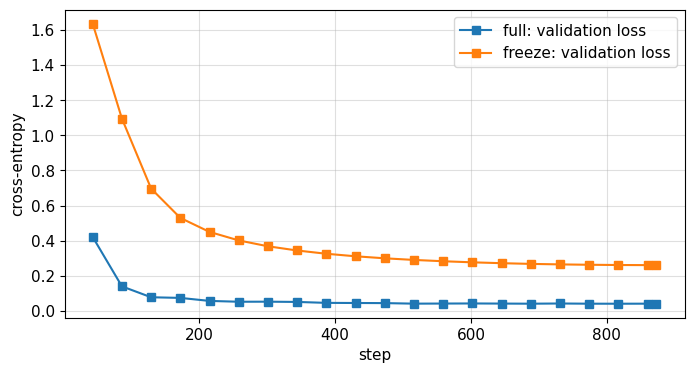

In [63]:
ABLATION = 'freeze'   # 'freeze' или 'all_subwords'
ablation = {}   # ваш код


def n_trainable(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


set_seed(SEED)
frozen_model = make_model()
frozen_history, frozen_seconds = train_ner(frozen_model, tokenized['train'], tokenized['validation'],
                                           freeze_encoder=True, out_dir='runs/freeze')
frozen_val_pred = predict_word_tags(frozen_model, val_tokens)

ablation = dict(
    setting=ABLATION, eval_split='validation', lr=LR, epochs=EPOCHS,
    full=dict(entity_scores(val_gold, val_pred), token_f1=token_f1(val_gold, val_pred),
              train_sec=train_seconds, trainable_params=n_trainable(model),
              final_eval_loss=[h['eval_loss'] for h in history if 'eval_loss' in h][-1]),
    freeze=dict(entity_scores(val_gold, frozen_val_pred), token_f1=token_f1(val_gold, frozen_val_pred),
                train_sec=frozen_seconds, trainable_params=n_trainable(frozen_model),
                final_eval_loss=[h['eval_loss'] for h in frozen_history if 'eval_loss' in h][-1]))
for name in ['full', 'freeze']:
    r = ablation[name]
    print(f'{name:<7} F1 micro {r["f1_micro"]:.4f}  F1 macro {r["f1_macro"]:.4f}  token F1 {r["token_f1"]:.4f}  '
          f'время {r["train_sec"]:.1f} c  обучаемых параметров {r["trainable_params"]:,}  eval loss {r["final_eval_loss"]:.4f}')
print(classification_report(val_gold, frozen_val_pred, digits=4, zero_division=0))

plt.figure(figsize=(8, 4))
for name, hist in [('full', history), ('freeze', frozen_history)]:
    plt.plot(*zip(*[(h['step'], h['eval_loss']) for h in hist if 'eval_loss' in h]), 's-', label=f'{name}: validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()
frozen_model.cpu()
del frozen_model

**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:** при замороженном энкодере обучаются только 2191 параметр головы вместо 29.1M, и F1 по сущностям на validation падает с 0.932 до 0.614 (на 32 пункта), token F1 - с 0.955 до 0.651. Сильнее всего страдает ORG: F1 0.36 (recall 0.30) против 0.73 у LOC и 0.70 у PER. Время обучения сокращается с 93.7 до 24.8 с, то есть в 3.8 раза: не нужен backward через энкодер и обновление оптимизатором 29M параметров, в том числе большой таблицы эмбеддингов. Причина падения качества: представления предобученного энкодера не настроены на границы и типы сущностей, а линейная голова над первым сабвордом сама не может учесть контекст соседних токенов (B против I, ORG против LOC). Кроме того, при LR = 2e-4, подобранном для полного дообучения, голова за 3 эпохи недоучивается: validation loss к концу 0.26 против 0.041 у полного дообучения и все еще снижается. Чтобы вывод был надежнее, я бы подобрала отдельный LR для замороженного варианта (1e-3 - 1e-2) и больше эпох, повторила оба варианта с 3 разными seed и посмотрела разброс, и проверила промежуточный вариант - разморозку последнего слоя энкодера

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:** дообучение маленького rubert-tiny2 (29M параметров, 92% из них в эмбеддингах) на Collection3 сработало: F1 по сущностям на test 0.934 (macro 0.931) против 0.56 у словарного бейзлайна и 0.04 у случайной головы (на validation), обучение заняло 94 с на T4. Токенный F1 выше (0.957), а среди ошибок 45% - неточные границы и только 7% пропусков: модель почти всегда находит сущность, но не всегда точно ее обрезает. Хуже всего распознается ORG (F1 0.865 на test против 0.955 у LOC и 0.974 у PER), на него же приходится большинство лишних спанов. Заморозка энкодера ускоряет обучение в 3.8 раза, но роняет F1 с 0.932 до 0.614: для NER нужно дообучать сам энкодер, а не только голову. Более крупный xlm-roberta-base (6.2) дает 0.970 на test ценой в 2.3 раза более долгого обучения и почти в 3 раза более медленного инференса. Модель неустойчива к регистру: при тексте целиком в нижнем или верхнем регистре F1 падает почти до нуля (0.05-0.07, 6.3). Ограничения: один новостной домен, всего три типа, неоднозначная разметка (кавычки, метонимия), один seed и короткий бюджет (3 эпохи без подбора гиперпараметров). Дальше я бы подобрала LR и число эпох по validation с несколькими seed, добавила CRF для согласованных BIO и аугментацию регистром и опечатками, и проверила модель на другом домене

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [64]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "cointegrated/rubert-tiny2", "revision": "e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae", "dataset": "RCC-MSU/collection3", "classes": ["LOC", "ORG", "PER"], "n_train": 9301, "n_val": 2153, "n_test": 1922, "params_total": 29098303, "ablation": {"setting": "freeze", "eval_split": "validation", "lr": 0.0002, "epochs": 3, "full": {"f1_micro": 0.9318317958547981, "f1_macro": 0.9294456257624734, "precision": 0.9193853427895982, "recall": 0.9446198688365315, "token_f1": 0.9545733998223922, "train_sec": 93.70950388000006, "trainable_params": 29098303, "final_eval_loss": 0.0407905
final F1 micro 0.9339


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [65]:
bonus = {}   # результаты бонусов, сохраняются в artifacts/bonus.json в конце ноутбука
if '6.1' in BONUS_TASKS:
    # ваш код
    pass

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:** не выполнялось

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [66]:
if '6.2' in BONUS_TASKS:
    MODEL2_ID = 'FacebookAI/xlm-roberta-base'
    REVISION2 = 'e73636d4f797dec63c3081bb6ed5c7b0bb3f2089'
    LR2 = 3e-5
    tokenizer2 = AutoTokenizer.from_pretrained(MODEL2_ID, revision=REVISION2)
    assert tokenizer2.is_fast
    tokenized2 = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names,
                          fn_kwargs=dict(tok=tokenizer2))

    def timed_predict(m, tok):
        if device.type == 'cuda':
            torch.cuda.synchronize()
        start = time.perf_counter()
        tags = predict_word_tags(m, val_tokens, tok=tok)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        return tags, time.perf_counter() - start

    set_seed(SEED)
    model2 = AutoModelForTokenClassification.from_pretrained(
        MODEL2_ID, revision=REVISION2, num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)
    if device.type == 'cuda':
        torch.cuda.reset_peak_memory_stats()
    history2, seconds2 = train_ner(model2, tokenized2['train'], tokenized2['validation'], lr=LR2,
                                   tok=tokenizer2, out_dir='runs/model2')
    peak_mem2 = torch.cuda.max_memory_allocated() / 2**30 if device.type == 'cuda' else None
    val_pred2, infer2 = timed_predict(model2, tokenizer2)
    test_pred2 = predict_word_tags(model2, test_tokens, tok=tokenizer2)
    _, infer1 = timed_predict(model, tokenizer)

    n_sub1 = sum(len(x) for x in tokenized['validation']['input_ids'])
    n_sub2 = sum(len(x) for x in tokenized2['validation']['input_ids'])
    bonus['6.2'] = {
        MODEL_ID: dict(params=sum(p.numel() for p in model.parameters()), train_sec=train_seconds, lr=LR,
                       val_infer_sec=infer1, val_subwords=n_sub1,
                       val=entity_scores(val_gold, val_pred), test=entity_scores(test_gold, test_pred)),
        MODEL2_ID: dict(params=sum(p.numel() for p in model2.parameters()), train_sec=seconds2, lr=LR2,
                        val_infer_sec=infer2, val_subwords=n_sub2, peak_train_mem_gb=peak_mem2,
                        val=entity_scores(val_gold, val_pred2), test=entity_scores(test_gold, test_pred2))}
    for name, r in bonus['6.2'].items():
        print(f'{name:<30} params {r["params"] / 1e6:6.1f}M  train {r["train_sec"]:7.1f} c  infer(val) {r["val_infer_sec"]:5.2f} c  '
              f'subwords(val) {r["val_subwords"]}  test F1 micro {r["test"]["f1_micro"]:.4f}  macro {r["test"]["f1_macro"]:.4f}')
    print(classification_report(test_gold, test_pred2, digits=4, zero_division=0))
    model2.cpu()
    del model2
    if device.type == 'cuda':
        torch.cuda.empty_cache()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '1.437', 'grad_norm': '2.447', 'learning_rate': '1.448e-05', 'epoch': '0.1478'}
{'eval_loss': '0.5422', 'eval_runtime': '2.753', 'eval_samples_per_second': '781.9', 'eval_steps_per_second': '12.35', 'epoch': '0.1478'}
{'loss': '0.3438', 'grad_norm': '2.804', 'learning_rate': '2.931e-05', 'epoch': '0.2955'}
{'eval_loss': '0.1155', 'eval_runtime': '2.829', 'eval_samples_per_second': '761', 'eval_steps_per_second': '12.02', 'epoch': '0.2955'}
{'loss': '0.09828', 'grad_norm': '4.577', 'learning_rate': '2.844e-05', 'epoch': '0.4433'}
{'eval_loss': '0.05891', 'eval_runtime': '2.906', 'eval_samples_per_second': '740.8', 'eval_steps_per_second': '11.7', 'epoch': '0.4433'}
{'loss': '0.07488', 'grad_norm': '2.474', 'learning_rate': '2.679e-05', 'epoch': '0.5911'}
{'eval_loss': '0.03812', 'eval_runtime': '2.807', 'eval_samples_per_second': '767.1', 'eval_steps_per_second': '12.11', 'epoch': '0.5911'}
{'loss': '0.05303', 'grad_norm': '2.989', 'learning_rate': '2.515e-05', 'epoch': '0.7388

**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:** xlm-roberta-base (277.5M параметров, почти в 10 раз больше, около 192M из них - эмбеддинги словаря 250k) лучше rubert-tiny2: test F1 micro 0.970 против 0.934 (+3.6 пункта), macro 0.968 против 0.931, на validation 0.971 против 0.932. Сильнее всего вырос ORG: 0.931 против 0.865 на test, у LOC 0.980 и у PER 0.993. Цена: обучение 214.7 с против 93.7 с (в 2.3 раза дольше), инференс на validation 3.84 с против 1.32 с (в 2.9 раза медленнее, отчасти потому что токенизатор xlm-r дает больше сабвордов: 74753 против 54365), пиковая память на обучении около 5 ГБ, веса около 1.1 ГБ против ~110 МБ. Честность сравнения: одинаковые сплиты и подмножества (`data`), одинаковые эпохи, batch, warmup, weight decay, seed и `MAX_LENGTH`, оценка одной функцией `predict_word_tags` по первому сабворду на тех же словах. Отличается только LR (2e-4 для tiny и 3e-5 для base), потому что у каждой модели свой рабочий диапазон, и одинаковый LR был бы нечестен к одной из них. Ограничение: один seed и без подбора гиперпараметров, но разница в 3.6 пункта заметно больше обычного разброса между seed, поэтому вывод о преимуществе base-модели скорее надежен

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [67]:
if '6.3' in BONUS_TASKS:
    TRANSLIT = dict(zip('абвгдеёжзийклмнопрстуфхцчшщъыьэюя',
                        ['a', 'b', 'v', 'g', 'd', 'e', 'e', 'zh', 'z', 'i', 'y', 'k', 'l', 'm', 'n', 'o', 'p', 'r', 's',
                         't', 'u', 'f', 'kh', 'ts', 'ch', 'sh', 'shch', '', 'y', '', 'e', 'yu', 'ya']))

    def translit(word):
        out = ''
        for ch in word:
            lat = TRANSLIT.get(ch.lower(), ch)
            out += lat.capitalize() if ch.isupper() else lat
        return out or word

    def typo(word, rng, p=0.3):
        if len(word) <= 3 or not word.isalpha() or rng.random() > p:
            return word
        i = rng.randrange(1, len(word) - 1)
        op = rng.choice(['delete', 'duplicate', 'swap'])
        if op == 'delete':
            return word[:i] + word[i + 1:]
        if op == 'duplicate':
            return word[:i] + word[i] + word[i:]
        return word[:i] + word[i + 1] + word[i] + word[i + 2:]

    rng_typo = random.Random(SEED)
    corruptions = {
        'clean': lambda ws: ws,
        'lower': lambda ws: [w.lower() for w in ws],
        'upper': lambda ws: [w.upper() for w in ws],
        'typos_30%': lambda ws: [typo(w, rng_typo) for w in ws],
        'translit': lambda ws: [translit(w) for w in ws],
    }
    bonus['6.3'] = {}
    for name, corrupt in corruptions.items():
        corrupted = [corrupt(list(ws)) for ws in val_tokens]
        assert all(len(a) == len(b) for a, b in zip(corrupted, val_tokens))
        pred = predict_word_tags(model, corrupted)
        bonus['6.3'][name] = dict(entity_scores(val_gold, pred),
                                  per_type={t: f1_score(val_gold, pred, average=None, zero_division=0)[i]
                                            for i, t in enumerate(sorted(ENTITY_TYPES))},
                                  subwords_per_word=sum(len(tokenizer(ws, is_split_into_words=True)['input_ids']) - 2
                                                        for ws in corrupted[:300]) / sum(len(ws) for ws in corrupted[:300]))
        r = bonus['6.3'][name]
        print(f'{name:<10} F1 micro {r["f1_micro"]:.4f}  P {r["precision"]:.4f}  R {r["recall"]:.4f}  '
              f'сабвордов на слово {r["subwords_per_word"]:.2f}  по типам ' +
              ', '.join(f'{t} {v:.3f}' for t, v in r['per_type'].items()))
        print('   ', ' '.join(corrupted[1])[:120])

clean      F1 micro 0.9318  P 0.9194  R 0.9446  сабвордов на слово 1.14  по типам LOC 0.949, ORG 0.866, PER 0.973
    Президент США Барак Обама в пятницу , 19 июня , назвал кандидатов на посты послов в Грузии и Таджикистане , сообщила пре
lower      F1 micro 0.0544  P 0.3645  R 0.0294  сабвордов на слово 1.24  по типам LOC 0.021, ORG 0.029, PER 0.095
    президент сша барак обама в пятницу , 19 июня , назвал кандидатов на посты послов в грузии и таджикистане , сообщила пре
upper      F1 micro 0.0693  P 0.0464  R 0.1370  сабвордов на слово 3.47  по типам LOC 0.173, ORG 0.049, PER 0.007
    ПРЕЗИДЕНТ США БАРАК ОБАМА В ПЯТНИЦУ , 19 ИЮНЯ , НАЗВАЛ КАНДИДАТОВ НА ПОСТЫ ПОСЛОВ В ГРУЗИИ И ТАДЖИКИСТАНЕ , СООБЩИЛА ПРЕ
typos_30%  F1 micro 0.8681  P 0.8482  R 0.8890  сабвордов на слово 1.43  по типам LOC 0.895, ORG 0.801, PER 0.903
    Президент США Барак Обама в пятницу , 19 иююня , нзавал кандидатов на посты послов в Грузии и Таджикистане , сообщила пр
translit   F1 micro 0.1248  P 0.0894  R 0.20

**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:** сильнее всего F1 роняет нижний регистр: 0.054 против 0.932 на чистом validation, затем верхний регистр (0.069) и транслит (0.125), а опечатки в 30% длинных слов портят меньше всего (0.868). В нижнем регистре теряется главный поверхностный признак сущности - заглавная буква: precision остается 0.36, а recall падает до 0.03, модель почти перестает находить сущности. В верхнем регистре слова режутся на много мелких сабвордов (3.47 сабворда на слово против 1.14), все слова выглядят как аббревиатуры, и модель плодит лишние спаны: precision 0.046 при recall 0.137. При транслите русские слова превращаются в латиницу, которую модель видела в основном в английских текстах: токенизатор режет их на 2.46 сабворда на слово и выученные признаки фамилий и топонимов пропадают. Но заглавные буквы остаются, поэтому F1 выше, чем при смене регистра, и лучше всего сохраняется PER (0.287). Опечатка меняет сабворды только одного слова (1.43 сабворда на слово в среднем), а заглавная буква и контекст предложения сохраняются, поэтому модель часто все равно находит сущность

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [68]:
if '6.4' in BONUS_TASKS:
    bench_batch = tokenizer(val_tokens[:32], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH,
                            padding=True, return_tensors='pt')

    def latency_ms(m, dev, n_runs=20, n_warmup=3):
        m.eval().to(dev)
        batch = {k: v.to(dev) for k, v in bench_batch.items()}
        with torch.inference_mode():
            for _ in range(n_warmup):
                m(**batch)
            if dev.type == 'cuda':
                torch.cuda.synchronize()
            start = time.perf_counter()
            for _ in range(n_runs):
                m(**batch)
            if dev.type == 'cuda':
                torch.cuda.synchronize()
        return (time.perf_counter() - start) / n_runs * 1000

    def check(name, m, dev):
        ms = latency_ms(m, dev)
        f1 = entity_scores(val_gold, predict_word_tags(m, val_tokens, dev=dev))['f1_micro']
        bonus['6.4'][name] = dict(device=str(dev), latency_ms=ms, val_f1_micro=f1)
        print(f'{name:<16} {str(dev):<5} {ms:8.2f} ms на батч {tuple(bench_batch["input_ids"].shape)}   val F1 micro {f1:.4f}')

    bonus['6.4'] = {}
    cpu = torch.device('cpu')
    torch.set_num_threads(max(1, os.cpu_count() or 1))
    fp32_cpu = copy.deepcopy(model).float().cpu()
    check('fp32', fp32_cpu, cpu)
    try:
        int8_cpu = torch.ao.quantization.quantize_dynamic(fp32_cpu, {torch.nn.Linear}, dtype=torch.qint8)
        check('int8 dynamic', int8_cpu, cpu)
    except Exception as e:
        print('int8 квантизация недоступна в этой версии torch:', repr(e)[:200])
    if device.type == 'cuda':
        check('fp32', copy.deepcopy(model).float(), device)
        check('fp16', copy.deepcopy(model).half(), device)
    model.to(device)

fp32             cpu     118.58 ms на батч (32, 48)   val F1 micro 0.9318


/tmp/ipykernel_4970/2820696118.py:32: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  int8_cpu = torch.ao.quantization.quantize_dynamic(fp32_cpu, {torch.nn.Linear}, dtype=torch.qint8)


int8 dynamic     cpu     185.23 ms на батч (32, 48)   val F1 micro 0.9302
fp32             cuda      6.66 ms на батч (32, 48)   val F1 micro 0.9318
fp16             cuda      4.87 ms на батч (32, 48)   val F1 micro 0.9319


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:** на GPU T4 fp16 против fp32 дает ускорение в 1.37 раза: 4.87 мс против 6.66 мс на батч из 32 предложений validation (32 × 48 сабвордов), F1 на validation не изменился (0.9319 против 0.9318). На CPU динамическая int8-квантизация Linear-слоев, наоборот, замедлила модель: 185.2 мс против 118.6 мс в fp32 (в 1.56 раза медленнее), F1 упал незначительно - с 0.9318 до 0.9302. Выигрыш зависит от модели: у rubert-tiny2 92% параметров - таблица эмбеддингов, но это просто lookup без вычислений, и квантизация ее не трогает. Все вычисления идут в 3 маленьких слоях энкодера (312 × 312, 312 × 600), где матричные умножения малы: выигрыш от int8-умножений не покрывает накладные расходы на квантизацию активаций на лету, а на GPU заметная доля времени уходит на запуск ядер, а не на сами вычисления. У base-модели с 12 широкими слоями доля матричных умножений больше, и квантизация и fp16 дали бы большее ускорение. Размер файла у tiny при int8 почти не уменьшился бы (эмбеддинги остаются в fp32), а у base уменьшился бы заметно

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

mean  порог 0: F1 0.9318 (P 0.9194, R 0.9446) | лучший порог 0.81: F1 0.9381 (P 0.9466, R 0.9298), прирост +0.0063
min   порог 0: F1 0.9318 (P 0.9194, R 0.9446) | лучший порог 0.76: F1 0.9379 (P 0.9493, R 0.9269), прирост +0.0061
проверка: F1 при пороге 0 = seqeval micro F1 = 0.9318


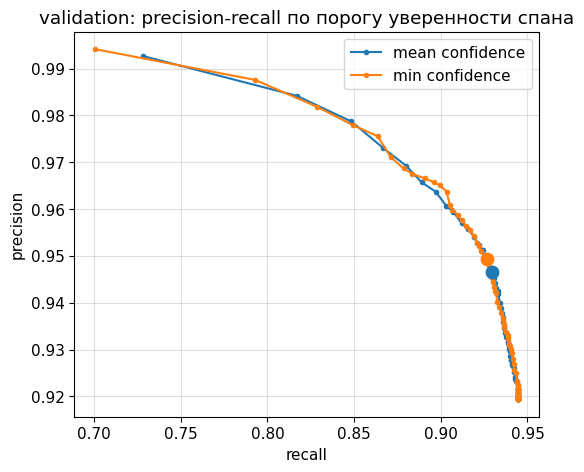

In [69]:
if '6.5' in BONUS_TASKS:
    val_tags_p, val_word_probs = predict_word_tags(model, val_tokens, return_probs=True)
    gold_span_sets = [set(bio_to_spans(g)) for g in val_gold]
    n_gold_spans = sum(len(g) for g in gold_span_sets)
    pred_spans_conf = [[(s, float(np.mean(probs[s[0]:s[1]])), float(np.min(probs[s[0]:s[1]])))
                        for s in bio_to_spans(tags)] for tags, probs in zip(val_tags_p, val_word_probs)]

    def pr_at(threshold, agg):
        tp = n_pred = 0
        for gold_set, spans in zip(gold_span_sets, pred_spans_conf):
            kept = {item[0] for item in spans if item[agg] >= threshold}
            tp += len(kept & gold_set)
            n_pred += len(kept)
        precision = tp / n_pred if n_pred else 1.0
        recall = tp / n_gold_spans if n_gold_spans else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        return precision, recall, f1

    thresholds = np.round(np.linspace(0, 0.99, 100), 2)
    bonus['6.5'] = {}
    plt.figure(figsize=(6, 5))
    for agg, name in [(1, 'mean'), (2, 'min')]:
        curve = np.array([pr_at(th, agg) for th in thresholds])
        best = int(curve[:, 2].argmax())
        bonus['6.5'][name] = dict(best_threshold=float(thresholds[best]), best_f1=float(curve[best, 2]),
                                  best_precision=float(curve[best, 0]), best_recall=float(curve[best, 1]),
                                  f1_at_0=float(curve[0, 2]))
        print(f'{name:<5} порог 0: F1 {curve[0, 2]:.4f} (P {curve[0, 0]:.4f}, R {curve[0, 1]:.4f}) | лучший порог '
              f'{thresholds[best]:.2f}: F1 {curve[best, 2]:.4f} (P {curve[best, 0]:.4f}, R {curve[best, 1]:.4f}), '
              f'прирост {curve[best, 2] - curve[0, 2]:+.4f}')
        plt.plot(curve[:, 1], curve[:, 0], '.-', label=f'{name} confidence')
        plt.scatter([curve[best, 1]], [curve[best, 0]], s=80, zorder=3)
    print('проверка: F1 при пороге 0 = seqeval micro F1 =', round(entity_scores(val_gold, val_tags_p)['f1_micro'], 4))
    plt.xlabel('recall')
    plt.ylabel('precision')
    plt.title('validation: precision-recall по порогу уверенности спана')
    plt.legend()
    plt.grid(True, alpha=0.4)
    plt.show()

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:** лучший порог по средней уверенности - 0.81: F1 0.9381 (P 0.9466, R 0.9298) против 0.9318 при пороге 0, прирост +0.0063, то есть около 0.6 пункта. По минимальной уверенности лучший порог 0.76: F1 0.9379 (P 0.9493, R 0.9269), прирост +0.0061. Прирост небольшой: спанов с низкой уверенностью немного, и порог в основном отсекает часть лишних спанов (precision растет с 0.919 до ~0.95) ценой небольшой потери recall (с 0.945 до ~0.93). Средняя уверенность сглаживает спан: длинный ORG с одним сомнительным словом сохраняется. Минимальная строже, она отбрасывает спан из-за одного слабого слова, поэтому ее лучший порог ниже (0.76 против 0.81), а при нем precision чуть выше и recall чуть ниже, чем у средней. Порог только выкидывает уже предсказанные спаны: число верных совпадений может лишь уменьшиться или остаться прежним, а пропущенные сущности (missed) и неверные границы от него не появятся. Поэтому recall при росте порога не растет, порог меняет только баланс precision и recall

In [70]:

(ARTIFACTS / 'bonus.json').write_text(json.dumps(json_ready(dict(bonus_tasks=sorted(BONUS_TASKS), fast_mode=FAST_MODE, **bonus)),
                                                 ensure_ascii=False, indent=2), encoding='utf-8')
print(sorted(bonus))

['6.2', '6.3', '6.4', '6.5']
